# Vamos a hacer la Tarea 1

En los estudios ecologicos modernos, la caracterizacion morfológica de las especies permite comprender los procesos de adaptación, segregación de nichos y dimorfismo sexual.

El conjunto de datos palmerpenguins contiene registros biogeograficos y mediciones físicas (masa corporal, longitud del pico, longitud de la aleta y sexo) de tres especies de pingüinos (Adelie, Chinstrap y Gentoo) recolectados en tres islas del Archipiélago Palmer en la Antartida.

Como analistas de datos, el objetivo es determinar si las características físicas difieren significativamente entre grupos geograficos y taxonnomicos, evaluar si los supuestos teoricos subyacentes a los métodos parametricos tradicionales se sostienen en la realidad, y modelar
la composición demográfica de estas poblaciones mediante estimaciones por intervalos.

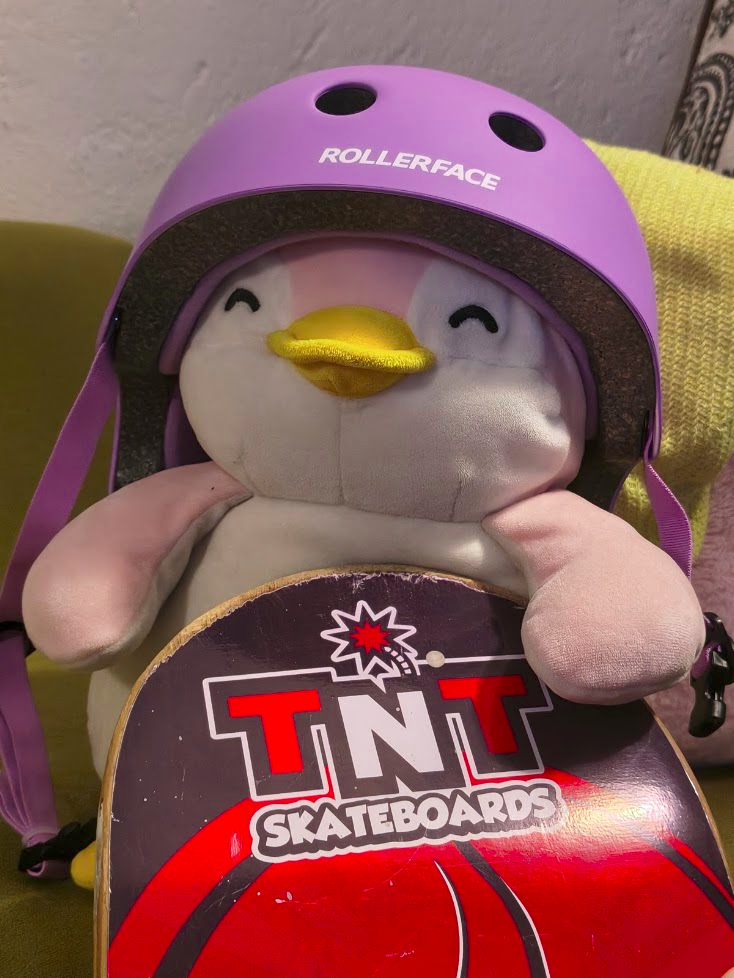

## Vamos traer los datos

In [1]:
#install.packages("palmerpenguins", dependencies = TRUE)

#La parte de graficar
library(ggplot2)
# Seafoam Cream palette
# #fff7e6, #e3ebd8, #bfd8c9, #8fbbae, #5f8e83

#Vamos a traer los datos
library(palmerpenguins)

#Vamos a traer herramientas
library(dplyr)
library(nortest)
library(car)


Attaching package: ‘palmerpenguins’


The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: carData


Attaching package: ‘car’


The following object is masked from ‘package:dplyr’:

    recode




In [2]:
data(penguins)
head(penguins)

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,NA,NA,NA,NA,NA,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007


## Vamos a hacer el análisis

Se solicita realizar un análisis estadıstico riguroso resolviendo punto por punto los siguientes requerimientos, justificando la elección de cada método en función de los datos observables:

### 1. Evaluación de Supuestos de Normalidad y Homocedasticidad: 
Antes de realizar contrastes paramétricos, es indispensable verificar la validez de sus supuestos básicos.
- Evalúe analíticamente si la variable longitud de la aleta (flipper length mm) sigue una distribución normal global y dentro de cada sexo utilizando alguna prueba de normalidad de su elección.

- Contraste la hipótesis de igualdad de varianzas (homocedasticidad) para la masa corporal (body mass g) entre los pingüinos machos y hembras mediante la prueba de Levene y la prueba F de Fisher. Compare y discuta los resultados de
ambas pruebas.

#### Vamos a evaluar analíticamente la parte de la longitud sigue una distribución

Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_bin()`).”


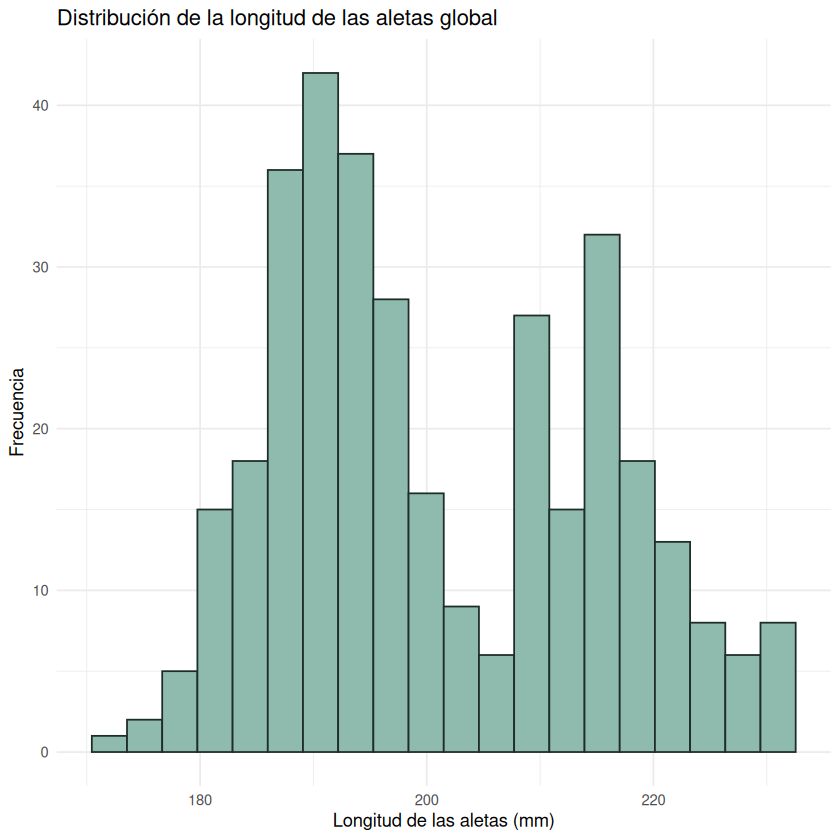

In [3]:
ggplot(data = penguins, aes(x = flipper_length_mm)) +
  geom_histogram(
    fill = "#8fbbae",
    color = "#1e2d29",
    bins = 20
  ) +
  labs(
    title = "Distribución de la longitud de las aletas global",
    x = "Longitud de las aletas (mm)",
    y = "Frecuencia"
  ) +
  theme_minimal()

In [4]:
shapiro.test(na.omit(penguins$flipper_length_mm))
print("Como el p-value es muy pequeño, entonces vamos Rechazar H0")
print("Es decir: No hay evidencia estadística para afirmar que se distribuyen normal")


	Shapiro-Wilk normality test

data:  na.omit(penguins$flipper_length_mm)
W = 0.95155, p-value = 3.54e-09


[1] "Como el p-value es muy pequeño, entonces vamos Rechazar H0"
[1] "Es decir: No hay evidencia estadística para afirmar que se distribuyen normal"


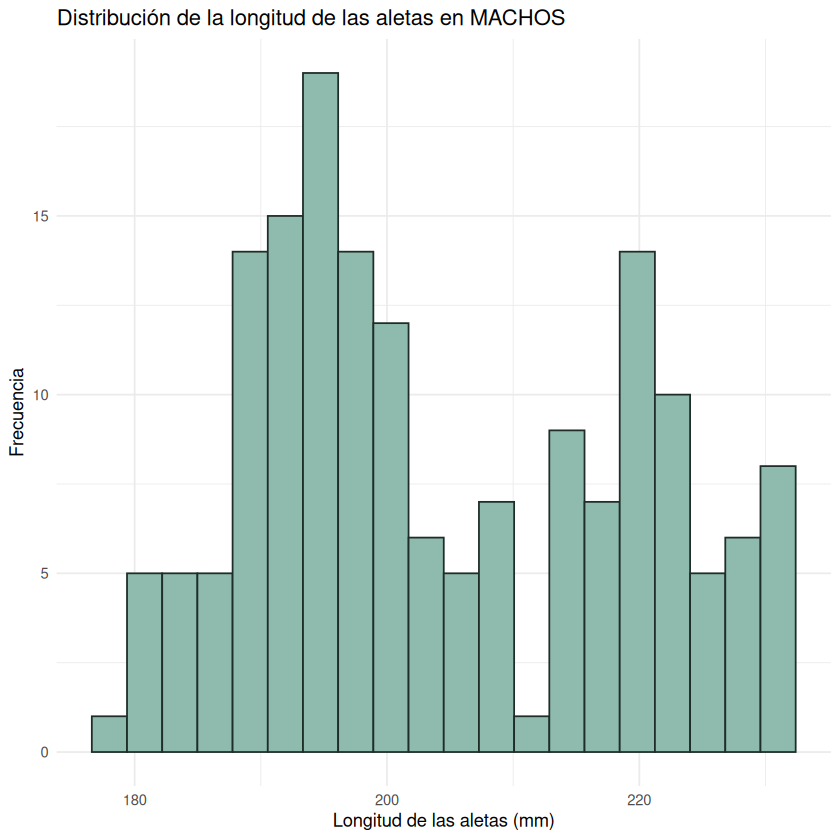

In [5]:
ggplot(data = filter(penguins, sex == 'male'), aes(x = flipper_length_mm)) +
  geom_histogram(
    fill = "#8fbbae",
    color = "#1e2d29",
    bins = 20
  ) +
  labs(
    title = "Distribución de la longitud de las aletas en MACHOS",
    x = "Longitud de las aletas (mm)",
    y = "Frecuencia"
  ) +
  theme_minimal()

In [6]:
shapiro.test(na.omit(filter(penguins, sex == 'male')$flipper_length_mm))
print("Como el p-value es muy pequeño, entonces vamos Rechazar H0")
print("Es decir: No hay evidencia estadística para afirmar que se distribuyen normal")


	Shapiro-Wilk normality test

data:  na.omit(filter(penguins, sex == "male")$flipper_length_mm)
W = 0.93593, p-value = 7.797e-07


[1] "Como el p-value es muy pequeño, entonces vamos Rechazar H0"
[1] "Es decir: No hay evidencia estadística para afirmar que se distribuyen normal"


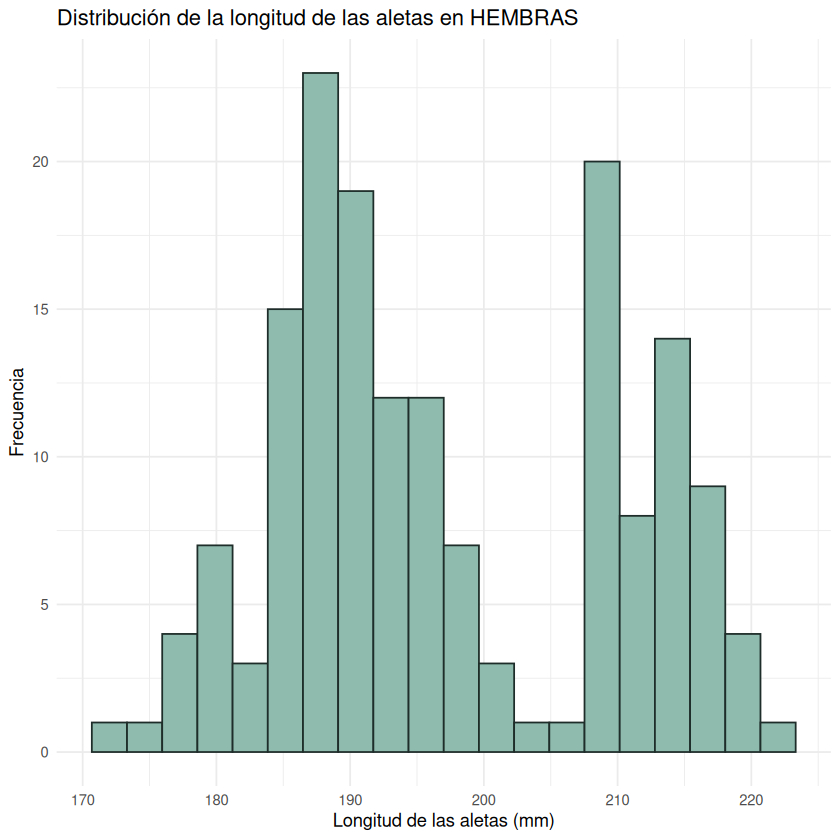

In [7]:
ggplot(data = filter(penguins, sex == 'female'), aes(x = flipper_length_mm)) +
  geom_histogram(
    fill = "#8fbbae",
    color = "#1e2d29",
    bins = 20
  ) +
  labs(
    title = "Distribución de la longitud de las aletas en HEMBRAS",
    x = "Longitud de las aletas (mm)",
    y = "Frecuencia"
  ) +
  theme_minimal()

In [8]:
shapiro.test(na.omit(filter(penguins, sex == 'female')$flipper_length_mm))
print("Como el p-value es muy pequeño, entonces vamos Rechazar H0")
print("Es decir: No hay evidencia estadística para afirmar que se distribuyen normal")


	Shapiro-Wilk normality test

data:  na.omit(filter(penguins, sex == "female")$flipper_length_mm)
W = 0.92654, p-value = 1.936e-07


[1] "Como el p-value es muy pequeño, entonces vamos Rechazar H0"
[1] "Es decir: No hay evidencia estadística para afirmar que se distribuyen normal"


Con esto podemos afirmar que el largo de sus aletitas NO se distribuye como normal

#### Ahora vamos con la parte de Homocedasticidad

In [25]:
shapiro.test(na.omit(penguins$body_mass_g))
print("Como el p-value es muy pequeño, entonces vamos Rechazar H0")
print("Es decir: No hay evidencia estadística para afirmar que se distribuyen normal")


	Shapiro-Wilk normality test

data:  na.omit(penguins$body_mass_g)
W = 0.95921, p-value = 3.679e-08


[1] "Como el p-value es muy pequeño, entonces vamos Rechazar H0"
[1] "Es decir: No hay evidencia estadística para afirmar que se distribuyen normal"


In [24]:
var_machos <- pull(na.omit(filter(penguins, sex== 'male')),var = "body_mass_g")
print("La varianza y la std de los machos")
var(var_machos)
sd(var_machos)

var_hembras <- pull(na.omit(filter(penguins, sex == 'female')), var = "body_mass_g")
print("La varianza y la std de las hembras")
var(var_hembras)
sd(var_hembras)

[1] "La varianza y la std de los machos"


[1] 620359.3

[1] 787.6289

[1] "La varianza y la std de las hembras"


[1] 443785.2

[1] 666.172

In [19]:
print("Vamos a hacer la prueba de Fisher")
var.test(var_machos, var_hembras)
print("Como salió abajo de 0.05, rechazamos H0, por lo que podemos decir que las varianzas no son iguales")

[1] "Vamos a hacer la prueba de Fisher"



	F test to compare two variances

data:  var_machos and var_hembras
F = 1.3979, num df = 167, denom df = 164, p-value = 0.03198
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 1.029398 1.897454
sample estimates:
ratio of variances 
          1.397882 


[1] "Como salió abajo de 0.05, rechazamos H0, por lo que podemos decir que las varianzas no son iguales"


In [20]:
print("Vamos a hacer la prueba de Levene")
leveneTest(body_mass_g ~ sex, data = na.omit(penguins))
print("Como salió abajo de 0.05, rechazamos H0, por lo que podemos decir que las varianzas no son iguales")

[1] "Vamos a hacer la prueba de Levene"


,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,1,6.058617,0.01434821
,331,NA,NA


[1] "Como salió abajo de 0.05, rechazamos H0, por lo que podemos decir que las varianzas no son iguales"


Nuestros resutlados indican que las varianzas no son iguales, con un alpha = 0.05, esto quiere decir que la variabilidad del peso es diferente dependiendo del sexo.
También es importante destacar que como los datos no cumplen el supuesto de  normalidad, la prueba de Levene es más robusta y sería la principal en nuestro análisis.

### 2. Estimación de Proporciones por Intervalos de Confianza

- Construya un intervalo de confianza del 95 % para la proporción poblacional de pingüinos hembra (sex == "female") utilizando el método exacto de Clopper-Pearson.

- Construya el intervalo análogo mediante el método asintótico de aproximación normal.

- Compare la amplitud de ambos intervalos y justifique cual de los dos utilizaría para su reporte.

In [63]:
print("Machos")
nmachos <- nrow(x = na.omit(filter(penguins, sex == 'male')))
nmachos

print("Hembras")
nhembras <- nrow(x = na.omit(filter(penguins, sex == 'female')))
nhembras

print("Proporcion de hembras:total")
nhembras/(nmachos+nhembras)

[1] "Machos"


[1] 168

[1] "Hembras"


[1] 165

[1] "Proporcion de hembras:total"


[1] 0.4954955

#### Método Exacto

In [64]:
binom.test(x = nhembras, n = (nmachos+nhembras), conf.level = 0.95)


	Exact binomial test

data:  nhembras and (nmachos + nhembras)
number of successes = 165, number of trials = 333, p-value = 0.9127
alternative hypothesis: true probability of success is not equal to 0.5
95 percent confidence interval:
 0.4405416 0.5505302
sample estimates:
probability of success 
             0.4954955 


#### Método Asintótico por aproximación normal

In [65]:
print("Primero a mano")
z <- qnorm(0.975)
n <- (nmachos+nhembras)
p <- nhembras/(nmachos+nhembras)
error_estandar <- sqrt((p * (1 - p)) / n)
margen_error <- z * error_estandar

limite_inferior <- p - margen_error
limite_superior <- p + margen_error

cat("Intervalo de confianza del 95%:", 
    limite_inferior, "a", limite_superior)

print("Ahora con la función de R")
prop.test(
  x = nhembras,
  n = nmachos + nhembras,
  conf.level = 0.95,
  correct = FALSE
)

[1] "Primero a mano"
Intervalo de confianza del 95%: 0.441795 a 0.549196[1] "Ahora con la función de R"



	1-sample proportions test without continuity correction

data:  nhembras out of nmachos + nhembras, null probability 0.5
X-squared = 0.027027, df = 1, p-value = 0.8694
alternative hypothesis: true p is not equal to 0.5
95 percent confidence interval:
 0.4421534 0.5489403
sample estimates:
        p 
0.4954955 


#### Conclusión

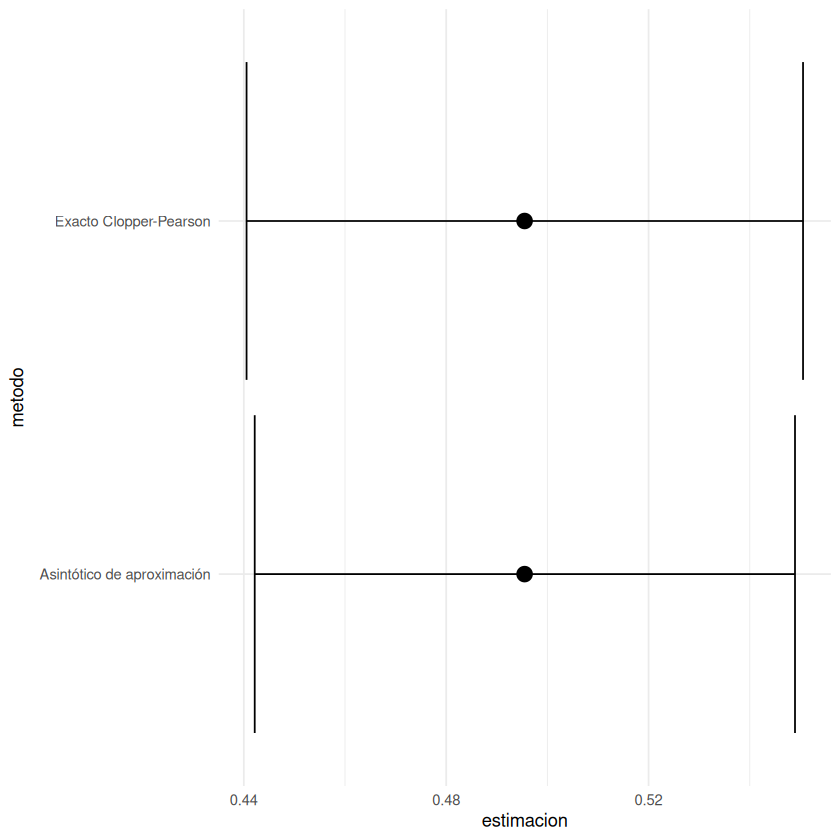

In [69]:
metodo <- c('Exacto Clopper-Pearson', 'Asintótico de aproximación')
estimacion <- c(0.4954955, 0.4954955)
intervalo_inferior <- c(0.4405416, 0.4421534)
intervalo_superior <- c(0.5505302, 0.5489403)
intervalos = data.frame(metodo, estimacion, intervalo_inferior, intervalo_superior)


ggplot(data = intervalos, aes(y = metodo)) +
  geom_errorbar(aes(xmin = intervalo_inferior, xmax = intervalo_superior)) +
  geom_point(aes(x = estimacion), size = 4) +
  theme_minimal()

In [70]:
intervalos$amplitud <- intervalo_superior - intervalo_inferior
head(intervalos)

,metodo,estimacion,intervalo_inferior,intervalo_superior,amplitud
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Exacto Clopper-Pearson,0.4954955,0.4405416,0.5505302,0.1099886
2,Asintótico de aproximación,0.4954955,0.4421534,0.5489403,0.1067869


Debido al tamaño de la muestra y aprovechando el teorema del límite central, usaríamos el método asintótico de aproximación

### 3. Estimación de Medias mediante Cantidad Pivotal: 

Filtre el conjunto de datos para trabajar únicamente con los pingüinos de la isla Biscoe. Utilizando el método de la cantidad pivotal basado en la distribución t de Student (asumiendo normalidad de la variable aunque no se demuestre con una prueba), calcule e interprete un intervalo de confianza del 95 % para la verdadera masa corporal promedio (body mass g) de dicha población.

In [83]:
biscoe <- na.omit(filter(penguins, island == "Biscoe"))
massa_b <- pull(.data = biscoe,var = "body_mass_g")

In [103]:
n <- nrow(biscoe)
x_mean <- mean(massa_b)
x_sd <- sd(x = massa_b)

t_critico <- qt(p = 0.975, df = n-1, lower.tail = TRUE)

ME <- t_critico * (x_sd / sqrt(n))

In [105]:
limite_inferior <- x_mean - ME
print("Límite inferior: ")
print(limite_inferior)

limite_superior <- x_mean + ME
print("Límite superior")
print(limite_superior)

amplitud = limite_superior - limite_inferior
print("Amplitud")
print(amplitud)

print("Media muestral")
print(x_mean)

[1] "Límite inferior: "
[1] 4596.848
[1] "Límite superior"
[1] 4841.495
[1] "Amplitud"
[1] 244.6473
[1] "Media muestral"
[1] 4719.172


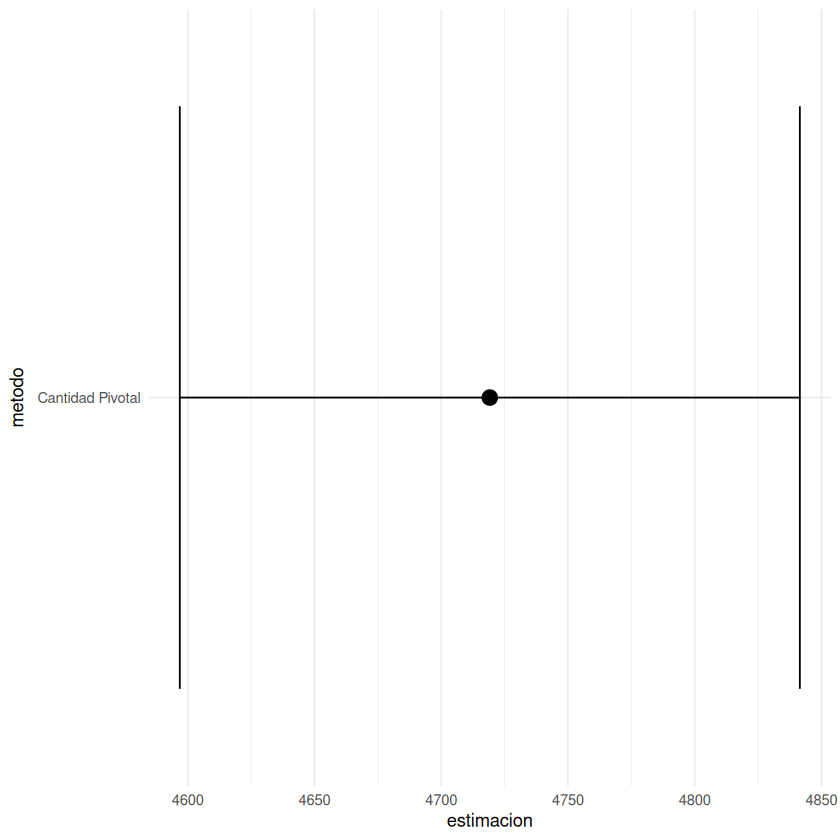

In [107]:
metodo <- c('Cantidad Pivotal')
estimacion <- c(4719.172)
intervalo_inferior <- c(4596.848)
intervalo_superior <- c(4841.495)
intervalos = data.frame(metodo, estimacion, intervalo_inferior, intervalo_superior)


ggplot(data = intervalos, aes(y = metodo)) +
  geom_errorbar(aes(xmin = intervalo_inferior, xmax = intervalo_superior)) +
  geom_point(aes(x = estimacion), size = 4) +
  theme_minimal()

### 4. Contraste de Hipótesis para la Diferencia de Medias (Dos Grupos): 
Se desea determinar si existe dimorfismo sexual respecto al peso de los individuos.

- Plantee y ejecute una prueba paramétrica (t de Student para muestras independientes) para contrastar si la masa corporal promedio (body mass g) difiere entre machos y hembras. Ajuste la prueba según el resultado de homocedasticidad del punto 1 (varianzas iguales o distintas).

- Como contraparte robusta, aplique la prueba no paramétrica de U de Mann-Whitney (Wilcoxon rank-sum) para evaluar la igualdad de distribuciones de peso entre ambos sexos. Explique las diferencias filosóficas entre contrastar diferencias en medias frente a diferencias en rangos/medianas.

- Concluya con lo anterior, si existen diferencias entre las masas corporales, ¿Por qué podría ser?

#### Vamos a empezar con el punto 1, ver si la masa de los machos en promedio difiere a la masa promedio de las hembras

In [ ]:
#t.test()